BÀI 1

In [9]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display

# Thiết lập giao diện biểu đồ sắc nét trên Colab
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

CONFIG = {
    "seed": 42,
    "val_size": 10_000,
    "batch_size": 64,
    "epochs": 40,
    "learning_rate": 1e-3,
    "checkpoint_path": "best_mlp_fashion.keras"
}

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

def seed_everything(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

seed_everything(CONFIG["seed"])
print(f"✅ TensorFlow Version : {tf.__version__}")
print(f"✅ Thiết bị tính toán : {tf.config.list_physical_devices('GPU') or 'CPU'}")

✅ TensorFlow Version : 2.21.0
✅ Thiết bị tính toán : CPU


BÀI 2

,Tập dữ liệu,Kích thước ảnh,Số lượng nhãn,Kiểu dữ liệu,Dải Pixel
0,Train Full,"(60000, 28, 28)",60000,uint8,0 - 255
1,Test,"(10000, 28, 28)",10000,uint8,0 - 255


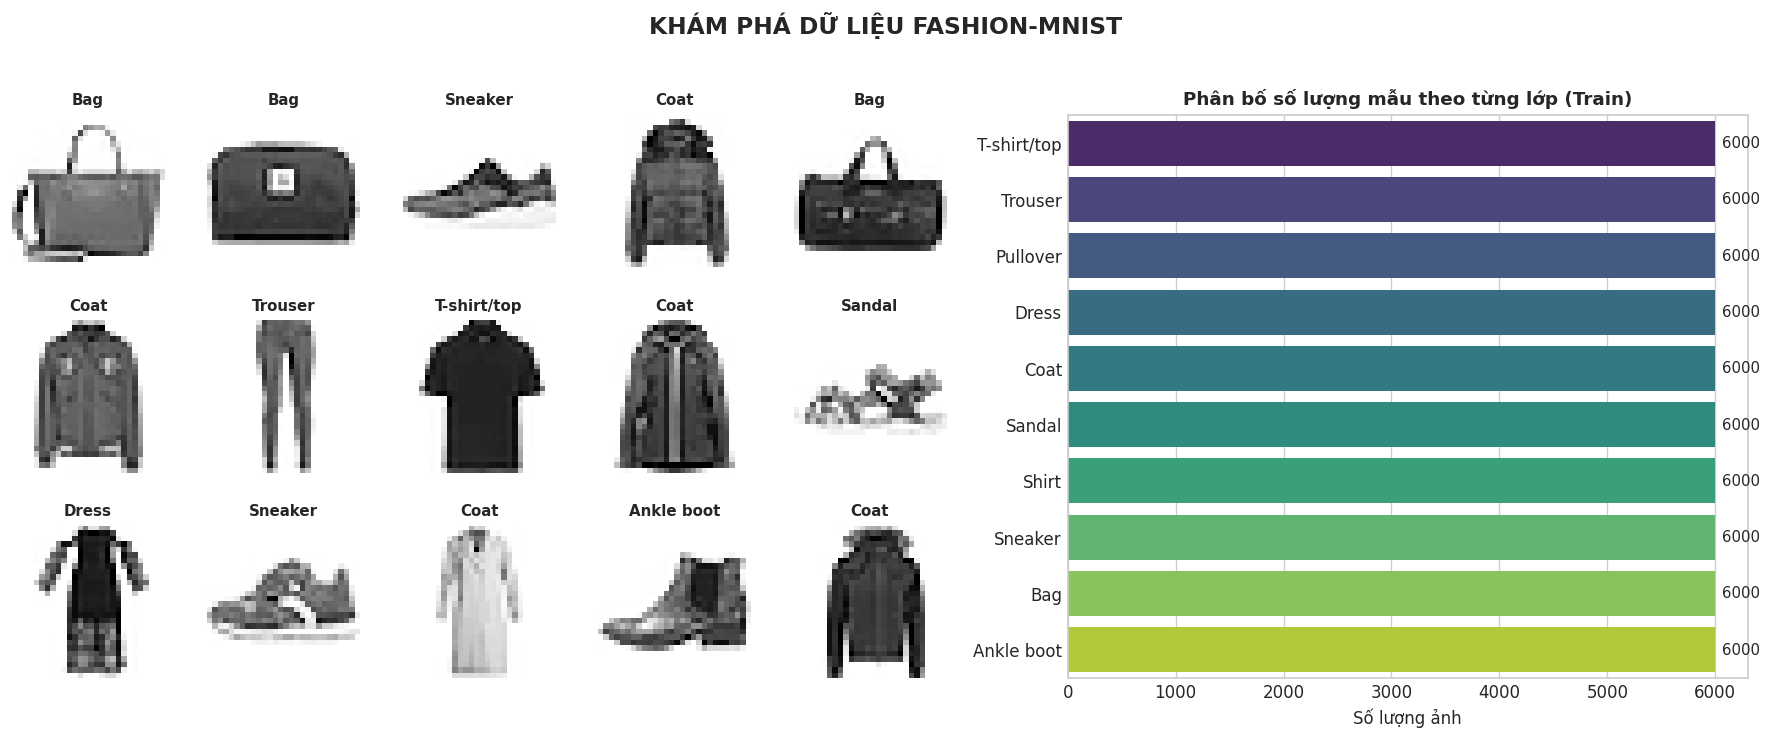

In [10]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Bảng thống kê tổng quan dữ liệu
summary_df = pd.DataFrame({
    "Tập dữ liệu": ["Train Full", "Test"],
    "Kích thước ảnh": [str(X_train_full.shape), str(X_test.shape)],
    "Số lượng nhãn": [len(y_train_full), len(y_test)],
    "Kiểu dữ liệu": [str(X_train_full.dtype), str(X_test.dtype)],
    "Dải Pixel": [f"{X_train_full.min()} - {X_train_full.max()}", f"{X_test.min()} - {X_test.max()}"]
})
display(summary_df)

# Trực quan hóa mẫu dữ liệu & Phân bố nhãn cùng lúc
fig = plt.figure(figsize=(15, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.4, 1])

# Cột trái: Lưới 15 ảnh mẫu ngẫu nhiên
sub_gs = gs[0].subgridspec(3, 5, wspace=0.15, hspace=0.35)
sample_indices = np.random.choice(len(X_train_full), 15, replace=False)
for idx, img_idx in enumerate(sample_indices):
    ax = fig.add_subplot(sub_gs[idx // 5, idx % 5])
    ax.imshow(X_train_full[img_idx], cmap="Greys")
    ax.set_title(f"{CLASS_NAMES[y_train_full[img_idx]]}", fontsize=9, fontweight="bold")
    ax.axis("off")

# Cột phải: Biểu đồ cột phân bố số lượng mẫu mỗi lớp
ax_bar = fig.add_subplot(gs[1])
unique, counts = np.unique(y_train_full, return_counts=True)
sns.barplot(x=counts, y=[CLASS_NAMES[i] for i in unique], palette="viridis", ax=ax_bar, hue=[CLASS_NAMES[i] for i in unique], legend=False)
ax_bar.set_title("Phân bố số lượng mẫu theo từng lớp (Train)", fontsize=11, fontweight="bold")
ax_bar.set_xlabel("Số lượng ảnh")
for container in ax_bar.containers:
    ax_bar.bar_label(container, padding=4, fontsize=9)

plt.suptitle("KHÁM PHÁ DỮ LIỆU FASHION-MNIST", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

BÀI 3

In [11]:
val_size = CONFIG["val_size"]

X_train = X_train_full[:-val_size].astype("float32") / 255.0
y_train = y_train_full[:-val_size]

X_val = X_train_full[-val_size:].astype("float32") / 255.0
y_val = y_train_full[-val_size:]

X_test_norm = X_test.astype("float32") / 255.0

def make_dataset(X, y, batch_size, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=CONFIG["seed"])
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, CONFIG["batch_size"], shuffle=True)
val_ds   = make_dataset(X_val, y_val, CONFIG["batch_size"])
test_ds  = make_dataset(X_test_norm, y_test, CONFIG["batch_size"])

print(f"✅ Kích thước tập Train      : {X_train.shape}")
print(f"✅ Kích thước tập Validation : {X_val.shape}")
print(f"✅ Kích thước tập Test       : {X_test_norm.shape}")

✅ Kích thước tập Train      : (50000, 28, 28)
✅ Kích thước tập Validation : (10000, 28, 28)
✅ Kích thước tập Test       : (10000, 28, 28)


BÀI 4

In [12]:
def build_mlp_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28), name="Input_Image"),
        tf.keras.layers.Flatten(name="Flatten"),

        # Block 1
        tf.keras.layers.Dense(256, use_bias=False, name="Dense_1"),
        tf.keras.layers.BatchNormalization(name="BatchNorm_1"),
        tf.keras.layers.Activation("relu", name="ReLU_1"),
        tf.keras.layers.Dropout(0.25, name="Dropout_1"),

        # Block 2
        tf.keras.layers.Dense(128, use_bias=False, name="Dense_2"),
        tf.keras.layers.BatchNormalization(name="BatchNorm_2"),
        tf.keras.layers.Activation("relu", name="ReLU_2"),
        tf.keras.layers.Dropout(0.2, name="Dropout_2"),

        # Output Layer
        tf.keras.layers.Dense(10, activation="softmax", name="Output_Softmax")
    ], name="Fashion_MLP_Pro")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=CONFIG["learning_rate"]),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    return model

model = build_mlp_model()
model.summary()

Model: "Fashion_MLP_Pro"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 256)            │       200,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_1                     │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_1 (Activation)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_2                     │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_2 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Softmax (Dense)          │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 236,298 (923.04 KB)

 Trainable params: 235,530 (920.04 KB)

 Non-trainable params: 768 (3.00 KB)

BÀI 5

In [13]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=CONFIG["checkpoint_path"],
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CONFIG["epochs"],
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8131 - loss: 0.5276 - val_accuracy: 0.8374 - val_loss: 0.4354 - learning_rate: 0.0010
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8545 - loss: 0.4003 - val_accuracy: 0.8623 - val_loss: 0.3687 - learning_rate: 0.0010
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8677 - loss: 0.3618 - val_accuracy: 0.8708 - val_loss: 0.3513 - learning_rate: 0.0010
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8748 - loss: 0.3384 - val_accuracy: 0.8765 - val_loss: 0.3360 - learning_rate: 0.0010
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8828 - loss: 0.3193 - val_accuracy: 0.8782 - val_loss: 0.3309 - learning_rate: 0.0010
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.8865 - loss: 0.3080 - val_accuracy: 0.8783 - val_loss: 0.3390 - learning_rate: 0.0010
Epoch 7/40
777/782 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8915 - loss: 0.2901
E

BÀI 6

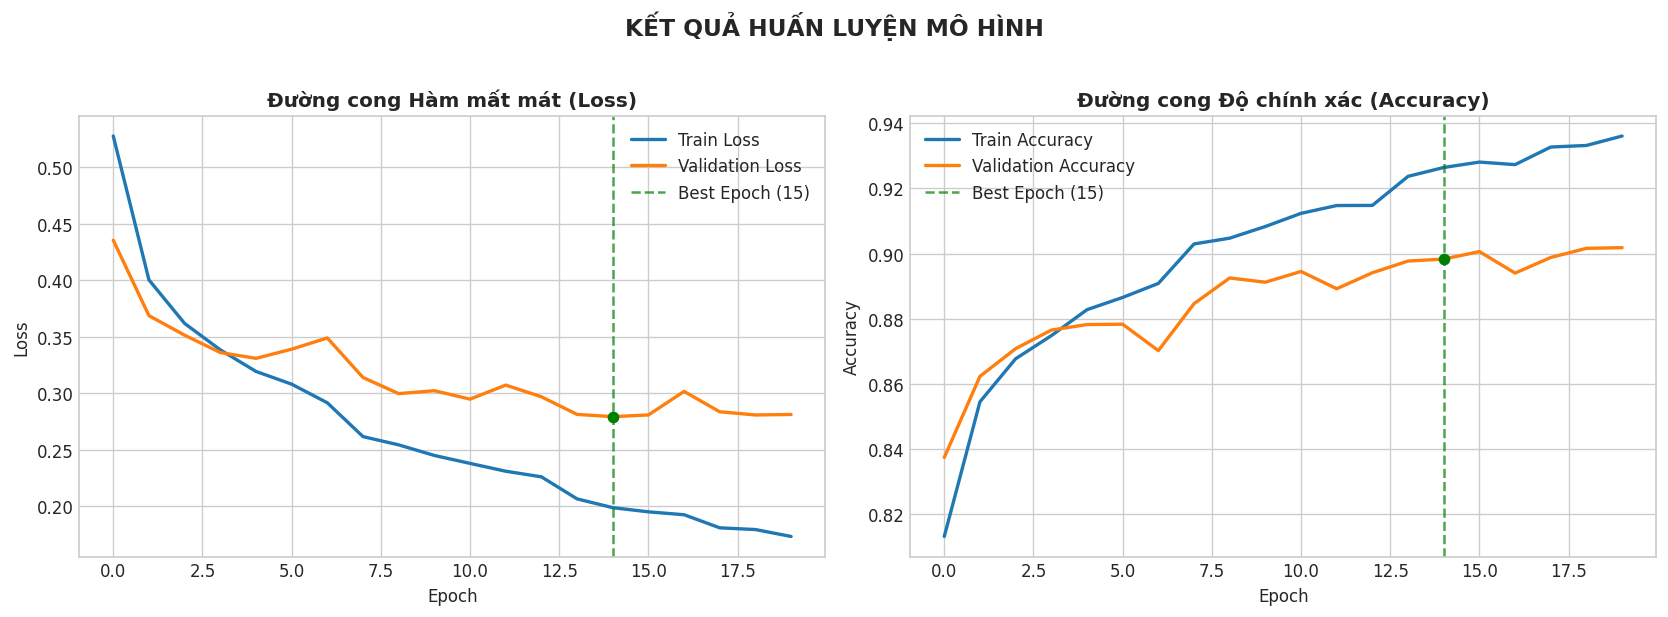

In [14]:
hist_df = pd.DataFrame(history.history)
best_epoch = hist_df["val_loss"].idxmin()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Loss
axes[0].plot(hist_df["loss"], label="Train Loss", linewidth=2, color="#1f77b4")
axes[0].plot(hist_df["val_loss"], label="Validation Loss", linewidth=2, color="#ff7f0e")
axes[0].axvline(best_epoch, color="green", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_epoch + 1})")
axes[0].scatter(best_epoch, hist_df.loc[best_epoch, "val_loss"], color="green", zorder=5)
axes[0].set_title("Đường cong Hàm mất mát (Loss)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Biểu đồ Accuracy
axes[1].plot(hist_df["accuracy"], label="Train Accuracy", linewidth=2, color="#1f77b4")
axes[1].plot(hist_df["val_accuracy"], label="Validation Accuracy", linewidth=2, color="#ff7f0e")
axes[1].axvline(best_epoch, color="green", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_epoch + 1})")
axes[1].scatter(best_epoch, hist_df.loc[best_epoch, "val_accuracy"], color="green", zorder=5)
axes[1].set_title("Đường cong Độ chính xác (Accuracy)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.suptitle("KẾT QUẢ HUẤN LUYỆN MÔ HÌNH", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

BÀI 7


BÀI 7: ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH TRÊN TẬP TEST
-> Test Loss     : 0.3012
-> Test Accuracy : 0.8950 (89.50%)

BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):
-------------------------------------------------------
              precision    recall  f1-score   support

 T-shirt/top     0.8435    0.8570    0.8502      1000
     Trouser     0.9929    0.9750    0.9839      1000
    Pullover     0.7985    0.8320    0.8149      1000
       Dress     0.9012    0.9030    0.9021      1000
        Coat     0.7963    0.8600    0.8269      1000
      Sandal     0.9765    0.9570    0.9667      1000
       Shirt     0.7671    0.6720    0.7164      1000
     Sneaker     0.9274    0.9710    0.9487      1000
         Bag     0.9759    0.9730    0.9745      1000
  Ankle boot     0.9714    0.9500    0.9606      1000

    accuracy                         0.8950     10000
   macro avg     0.8951    0.8950    0.8945     10000
weighted avg     0.8951    0.8950    0.8945     10000



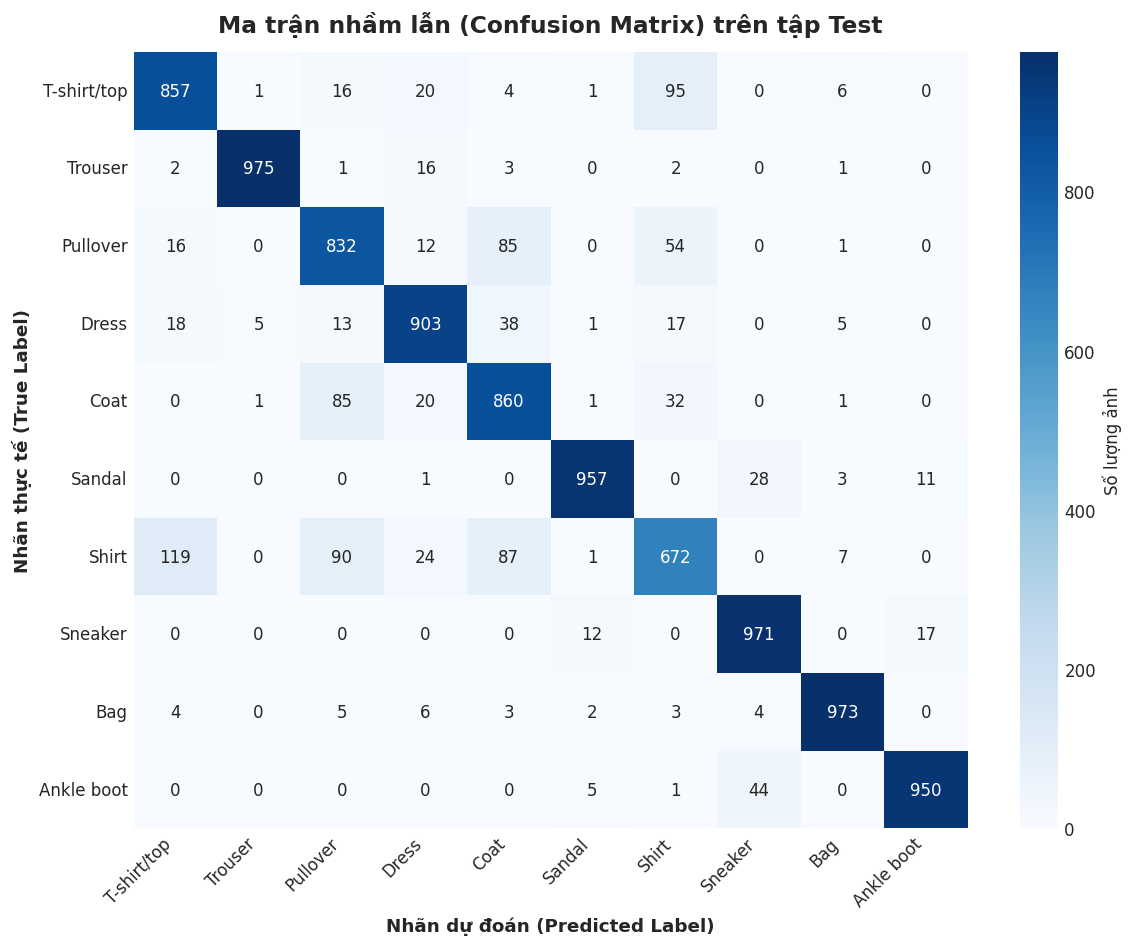


Tổng số mẫu dự đoán sai trên tập Test: 1050 / 10000 ảnh


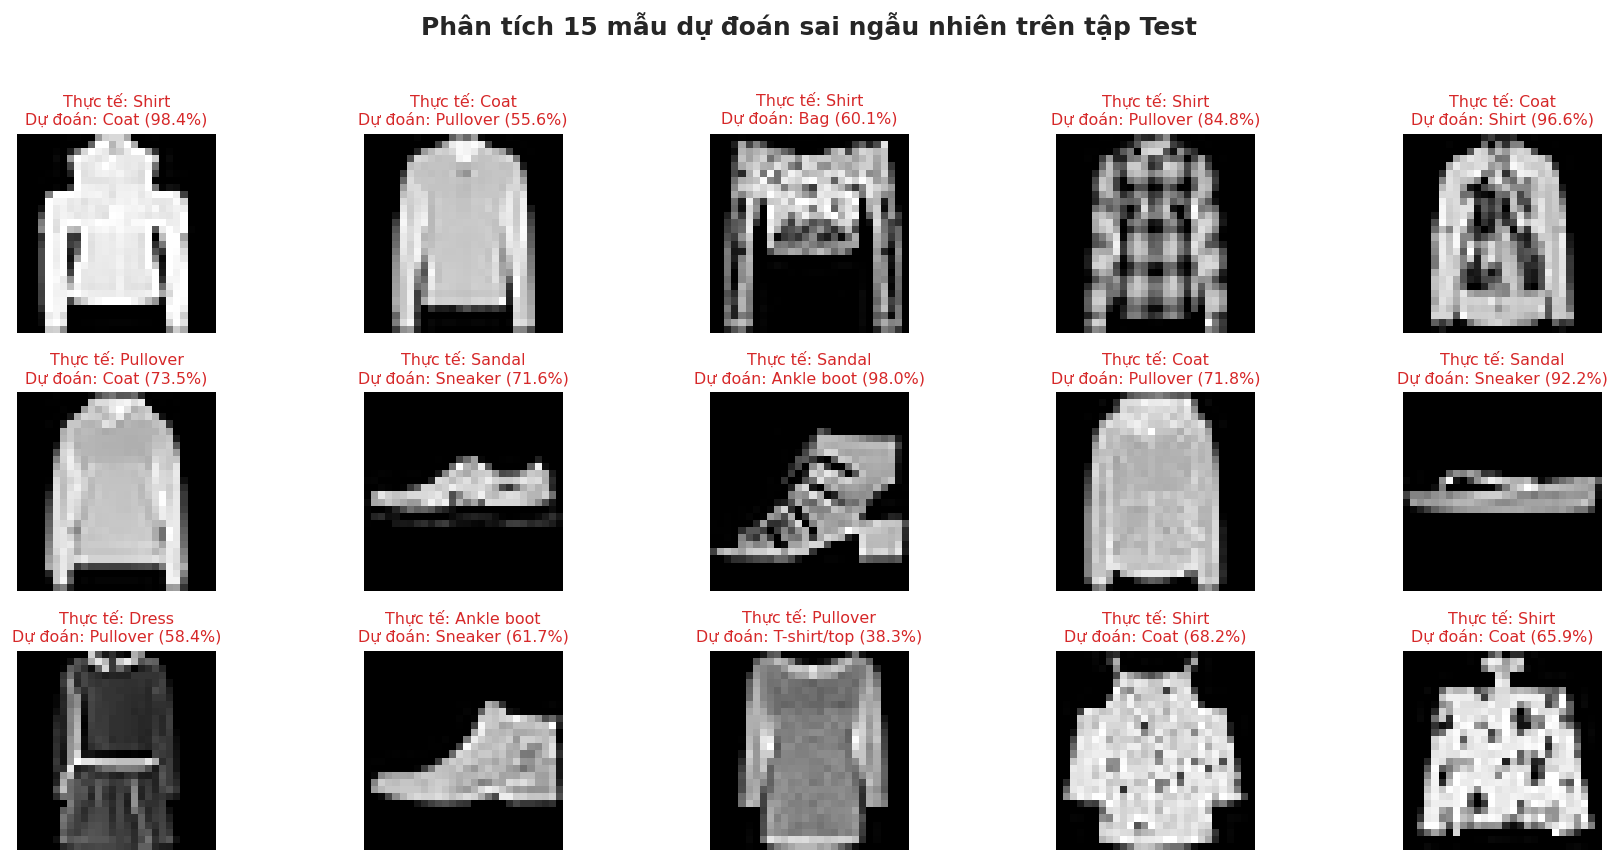

In [19]:
# --- BÀI 7: ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST & TRỰC QUAN HÓA KẾT QUẢ ---
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("\n" + "="*55)
print("BÀI 7: ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH TRÊN TẬP TEST")
print("="*55)

# 1. Đánh giá tổng thể trên tập Test
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"-> Test Loss     : {test_loss:.4f}")
print(f"-> Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)")

# 2. Dự đoán nhãn trên toàn bộ tập Test
y_pred_probs = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. In báo cáo phân loại chi tiết (Precision, Recall, F1-Score)
print("\nBÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):")
print("-" * 55)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

# 4. Vẽ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar_kws={'label': 'Số lượng ảnh'}
)
plt.title('Ma trận nhầm lẫn (Confusion Matrix) trên tập Test', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Nhãn dự đoán (Predicted Label)', fontsize=11, fontweight='bold')
plt.ylabel('Nhãn thực tế (True Label)', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 5. Trực quan hóa 15 mẫu dự đoán sai (Error Analysis)
misclassified_idx = np.where(y_pred != y_test)[0]
print(f"\nTổng số mẫu dự đoán sai trên tập Test: {len(misclassified_idx)} / {len(y_test)} ảnh")

np.random.seed(CONFIG["seed"])
sample_err_idx = np.random.choice(misclassified_idx, 15, replace=False)

plt.figure(figsize=(15, 7))
plt.suptitle("Phân tích 15 mẫu dự đoán sai ngẫu nhiên trên tập Test", fontsize=15, fontweight='bold', y=1.02)

for i, idx in enumerate(sample_err_idx):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[idx], cmap='gray')
    true_label = CLASS_NAMES[y_test[idx]]
    pred_label = CLASS_NAMES[y_pred[idx]]
    conf = y_pred_probs[idx][y_pred[idx]] * 100

    plt.title(f"Thực tế: {true_label}\nDự đoán: {pred_label} ({conf:.1f}%)", fontsize=9.5, color='#d62728')
    plt.axis('off')

plt.tight_layout()
plt.show()